# 13 — Pontuação externa das previsões congeladas de 2026

Execute somente depois de congelar as previsões do estágio anterior. Este notebook abre os alvos somente para pontuação. Experimentos posteriores podem usar consumos anteriores à origem como histórico explicitamente identificado. Ele não modifica a previsão congelada nem recalibra o modelo. O baseline de 2026 é denominado “estimativa da nutricionista” e fica separado da série de reservas estudantis usada em 2023–2025.

As diferenças entre plano e consumo são excesso e falta potenciais; sem registros de produção, sobras físicas e refeições não atendidas, não são medidas de desperdício ou serviço negado. A equivalência financeira multiplicando quantidade planejada pela tarifa contratual é uma simulação bruta, sem descontos, regras de faturamento ou penalidades.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Raiz do projeto não localizada.")
RESULTS = ROOT / "resultados" / "validacao_2026"
FORECAST_PATH = RESULTS / "previsoes_cegas_2026.csv"
MANIFEST_PATH = RESULTS / "manifesto_previsoes_cegas_2026.json"
ACTUAL_PATH = ROOT / "data" / "validacao_2026_restrita" / "consumo_real_2026.csv"
GASTOS_PATH = ROOT / "dados" / "financeiro" / "Gastos_Refeicao.xlsx"
FIG_DIR = ROOT / "resultados" / "figuras_dissertacao"
FIG_DIR.mkdir(parents=True, exist_ok=True)


## 1. Verificar o congelamento e só então abrir o resultado observado

In [2]:
if not FORECAST_PATH.exists() or not MANIFEST_PATH.exists():
    raise FileNotFoundError("Execute primeiro o estágio de previsão cega.")
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
actual_hash = hashlib.sha256(FORECAST_PATH.read_bytes()).hexdigest()
if actual_hash != manifest["sha256_previsoes"]:
    raise ValueError("A previsão congelada foi alterada depois do registro do hash.")

forecast = pd.read_csv(FORECAST_PATH, encoding="utf-8-sig")
actual = pd.read_csv(ACTUAL_PATH, encoding="utf-8-sig", dtype=str, keep_default_na=False, sep=None, engine="python")
date_col = next((c for c in ["data", "DATA", "date", "DATA_ALVO"] if c in actual.columns), None)
value_col = next((c for c in ["consumo_total", "consumo", "refeicoes", "refeições", "quantidade", "CONSUMO"] if c in actual.columns), None)
if date_col is None or value_col is None:
    raise ValueError(f"Esquema do consumo restrito não reconhecido: {actual.columns.tolist()}")
actual = actual[[date_col, value_col]].rename(columns={date_col: "data", value_col: "consumo_observado"})
actual["data"] = pd.to_datetime(actual["data"], dayfirst=True, errors="coerce", format="mixed").dt.normalize()
actual["consumo_observado"] = pd.to_numeric(actual["consumo_observado"].replace("", np.nan), errors="coerce")
actual = actual.dropna(subset=["data", "consumo_observado"])
actual = actual.loc[actual["data"].dt.year.eq(2026)]
if actual["data"].duplicated().any():
    raise ValueError("Há mais de um consumo observado por data no arquivo de validação.")

forecast["data"] = pd.to_datetime(forecast["data"], errors="raise").dt.normalize()
forecast["origem"] = pd.to_datetime(forecast["origem"], errors="raise").dt.normalize()
joined = forecast.merge(actual, on="data", how="inner", validate="one_to_one")
if joined.empty:
    raise ValueError("Nenhuma data com previsão congelada e consumo observado foi pareada.")
joined["erro"] = joined["previsao_consumo"] - joined["consumo_observado"]
joined["erro_abs"] = joined["erro"].abs()


## 2. Métricas pareadas: previsão, margem e estimativa da nutricionista

In [3]:
def plan_metrics(name, planned):
    error = planned - joined["consumo_observado"]
    excess = np.maximum(error, 0)
    shortage = np.maximum(-error, 0)
    return {
        "metodo": name,
        "n_datas": int(len(joined)),
        "MAE_refeicoes": float(np.abs(error).mean()),
        "WAPE_pct": float(np.abs(error).sum() / joined["consumo_observado"].sum() * 100),
        "vies_refeicoes": float(error.mean()),
        "excesso_potencial_total": int(excess.sum()),
        "falta_potencial_total": int(shortage.sum()),
        "dias_sem_deficit": int((error >= 0).sum()),
        "perda_hipotetica_2a1": float((2 * shortage + excess).mean()),
    }

joined_todas = joined.copy()
joined = joined.loc[pd.to_numeric(joined["reservas_nutricionista"], errors="coerce").notna()].copy()
if joined.empty: raise ValueError("Sem coorte comum para modelo e nutricionista.")
joined_todas = joined.copy()
joined = joined.loc[pd.to_numeric(joined["reservas_nutricionista"], errors="coerce").notna()].copy()
if joined.empty: raise ValueError("Sem coorte comum para modelo e nutricionista.")
rows = [
    plan_metrics("Previsao pura", joined["quantidade_pura"].to_numpy(dtype=float)),
    plan_metrics("Previsao + margem fixa de 10", joined["quantidade_margem_10"].to_numpy(dtype=float)),
]
paired = joined.loc[pd.to_numeric(joined["reservas_nutricionista"], errors="coerce").notna()].copy()
if not paired.empty:
    reserve_error = paired["reservas_nutricionista"].astype(float) - paired["consumo_observado"]
    reserve_excess = reserve_error.clip(lower=0)
    reserve_shortage = (-reserve_error).clip(lower=0)
    rows.append({
        "metodo": "Estimativa da nutricionista (2026)",
        "n_datas": int(len(paired)),
        "MAE_refeicoes": float(reserve_error.abs().mean()),
        "WAPE_pct": float(reserve_error.abs().sum() / paired["consumo_observado"].sum() * 100),
        "vies_refeicoes": float(reserve_error.mean()),
        "excesso_potencial_total": int(reserve_excess.sum()),
        "falta_potencial_total": int(reserve_shortage.sum()),
        "dias_sem_deficit": int((reserve_error >= 0).sum()),
        "perda_hipotetica_2a1": float((2 * reserve_shortage + reserve_excess).mean()),
    })
metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / "metricas_2026_pareadas.csv", index=False, encoding="utf-8-sig")
joined.to_csv(RESULTS / "previsoes_e_consumos_pareados_2026.csv", index=False, encoding="utf-8-sig")
display(metrics.round(2))
print(f"Cobertura da validação: {len(joined)} de {forecast['data'].nunique()} datas com previsão; consumo observado até {actual['data'].max().date()}.")


,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial_total,falta_potencial_total,dias_sem_deficit,perda_hipotetica_2a1
0,Previsao pura,123,57.41,34.33,-48.16,569,6493,19,110.20
1,Previsao + margem fixa de 10,123,51.04,30.52,-38.16,792,5486,26,95.64
2,Estimativa da nutricionista (2026),123,26.21,15.67,15.43,2561,663,75,31.60


Cobertura da validação: 123 de 145 datas com previsão; consumo observado até 2026-08-31.


## 3. Cenário financeiro simplificado e limites de interpretação

In [4]:
if GASTOS_PATH.exists():
    import openpyxl
    ws = openpyxl.load_workbook(GASTOS_PATH, data_only=True, read_only=True).active
    invoices = pd.DataFrame(
        [[ws.cell(i, 1).value, ws.cell(i, 2).value, ws.cell(i, 3).value,
          ws.cell(i, 4).value, ws.cell(i, 5).value, ws.cell(i, 6).value, ws.cell(i, 7).value]
         for i in range(2, ws.max_row + 1)],
        columns=["mes", "empresa", "quantidade_faturada", "tarifa", "valor_total", "desconto", "valor_pago"],
    )
    invoices["mes"] = pd.to_datetime(invoices["mes"], errors="coerce")
    invoices_2026 = invoices.loc[invoices["mes"].dt.year.eq(2026)].copy()
    invoices_2026.to_csv(RESULTS / "faturas_2026_origem.csv", index=False, encoding="utf-8-sig")
    monthly_paid = invoices_2026.groupby(invoices_2026["mes"].dt.to_period("M"), as_index=False).agg(
        quantidade_faturada=("quantidade_faturada", "sum"), valor_pago=("valor_pago", "sum"), tarifa_media=("tarifa", "mean")
    )
    paid_total = float(pd.to_numeric(invoices_2026["valor_pago"], errors="coerce").fillna(0).sum())
    rates = invoices_2026[["mes", "tarifa"]].dropna().copy()
    rates["periodo"] = rates["mes"].dt.to_period("M")
    rates = rates.groupby("periodo")["tarifa"].mean()
    joined["periodo"] = joined["data"].dt.to_period("M")
    paired_cost = joined.loc[pd.to_numeric(joined["reservas_nutricionista"], errors="coerce").notna()].copy()
    paired_cost["tarifa_referencia"] = paired_cost["periodo"].map(rates)
    paired_cost = paired_cost.dropna(subset=["tarifa_referencia"])
    if not paired_cost.empty:
        cost_rows = []
        for label, col in [("Previsao pura", "quantidade_pura"), ("Previsao + margem 10", "quantidade_margem_10"), ("Estimativa da nutricionista", "reservas_nutricionista")]:
            total = float((paired_cost[col].astype(float) * paired_cost["tarifa_referencia"]).sum())
            cost_rows.append({"cenário": label, "n_datas_pareadas": int(len(paired_cost)), "valor_bruto_simulado_R$": total})
        cost_scenarios = pd.DataFrame(cost_rows)
        cost_scenarios.to_csv(RESULTS / "simulacao_bruta_tarifa_2026.csv", index=False, encoding="utf-8-sig")
        display(monthly_paid)
        display(cost_scenarios.round(2))
        print(f"Valor pago real registrado na planilha em 2026 (linhas preenchidas): R$ {paid_total:,.2f}")
        print("Os cenários de quantidade × tarifa são equivalentes brutos, não pagamentos previstos nem economia realizada.")
else:
    print("Planilha de gastos não localizada; métricas operacionais permanecem disponíveis.")


,mes,quantidade_faturada,valor_pago,tarifa_media
0,2026-01,0.00,0.00,NaN
1,2026-02,2383.00,33362.00,14.0
2,2026-03,3891.13,54475.82,14.0
3,2026-04,3454.00,48356.00,14.0
4,2026-05,3314.00,46396.00,14.0
5,2026-06,3868.00,54152.00,14.0
6,2026-07,946.00,13244.00,14.0
7,2026-08,3800.00,53200.00,14.0
8,2026-09,0.00,0.00,14.0
9,2026-10,0.00,0.00,14.0


,cenário,n_datas_pareadas,valor_bruto_simulado_R$
0,Previsao pura,123,205044.0
1,Previsao + margem 10,123,222264.0
2,Estimativa da nutricionista,123,314552.0


Valor pago real registrado na planilha em 2026 (linhas preenchidas): R$ 303,185.82
Os cenários de quantidade × tarifa são equivalentes brutos, não pagamentos previstos nem economia realizada.


## 4. Representações para a dissertação

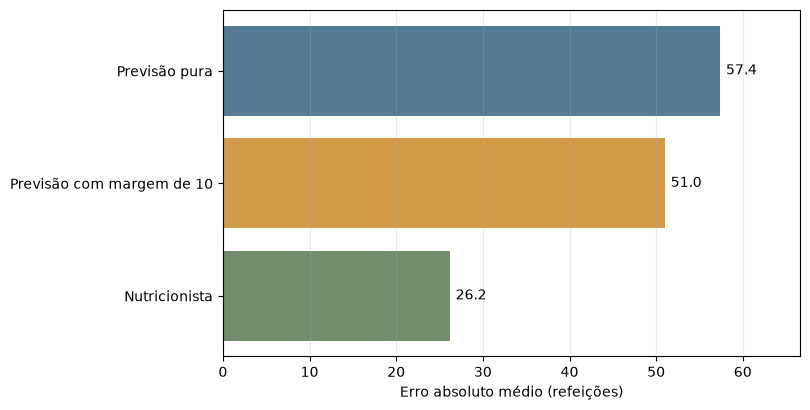

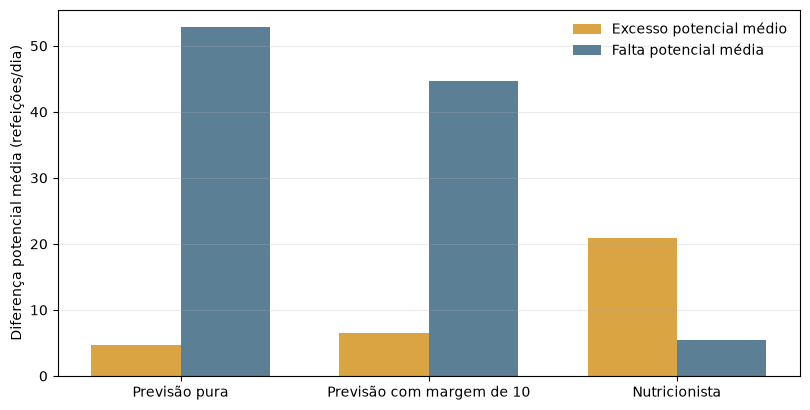

In [5]:
compare = metrics.loc[metrics["metodo"].isin(["Previsao pura", "Previsao + margem fixa de 10", "Estimativa da nutricionista (2026)"])].copy()
labels = ["Previsão pura", "Previsão com margem de 10", "Nutricionista"]
compare = compare.set_index("metodo").loc[["Previsao pura", "Previsao + margem fixa de 10", "Estimativa da nutricionista (2026)"]]
fig, ax = plt.subplots(figsize=(8.2, 4.2))
values = compare["MAE_refeicoes"].to_numpy()
bars = ax.barh(labels[::-1], values[::-1], color=["#738C6B", "#D39A4A", "#547C94"])
ax.set_xlabel("Erro absoluto médio (refeições)")
ax.grid(axis="x", alpha=.25)
ax.bar_label(bars, fmt="%.1f", padding=4)
ax.set_xlim(0, max(values) * 1.16)
fig.tight_layout()
fig.savefig(FIG_DIR / "validacao_2026_mae_modelo_nutricionista.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "validacao_2026_mae_modelo_nutricionista.pdf", bbox_inches="tight")
plt.show()

source = [joined["quantidade_pura"], joined["quantidade_margem_10"], joined["reservas_nutricionista"]]
excesses, shortages = [], []
for series in source:
    mask = series.notna()
    err = series[mask].astype(float).to_numpy() - joined.loc[mask, "consumo_observado"].to_numpy(dtype=float)
    excesses.append(np.maximum(err, 0).sum() / max(1, mask.sum()))
    shortages.append(np.maximum(-err, 0).sum() / max(1, mask.sum()))
fig, ax = plt.subplots(figsize=(8.2, 4.2))
positions = np.arange(len(labels))
width = .36
ax.bar(positions - width/2, excesses, width, label="Excesso potencial médio", color="#D9A441")
ax.bar(positions + width/2, shortages, width, label="Falta potencial média", color="#5B7F95")
ax.set_xticks(positions, labels)
ax.set_ylabel("Diferença potencial média (refeições/dia)")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "validacao_2026_tradeoff_potencial.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "validacao_2026_tradeoff_potencial.pdf", bbox_inches="tight")
plt.show()


## Registro de limitações

- O conjunto com resultado observado pode terminar antes de 2 de outubro; a cobertura aparece junto às métricas.
- O método 2026 da nutricionista difere das reservas feitas por estudantes até 2025. A comparação é útil para avaliar o processo atual, mas representa mudança de regime operacional.
- Os registros financeiros mensais não se reconciliam diretamente com a soma de consumo ou reservas diárias e incluem ajustes; qualquer quantidade multiplicada por tarifa é um cenário simplificado.
- Não há dados diários de produção, sobras físicas, faltas atendidas nem penalidades contratuais; os resultados não permitem afirmar desperdício evitado, alunos atendidos a mais ou economia realizada.
- Setembro de 2026 sem consumo registrado não entra na pontuação, ainda que existam previsões para datas desse mês.
